# Parcial Minería de Datos 2025

**Alumno:** Cussi Nicolás Alejandro

## Etapa 1: Selección y Exploración de Datos
---
### 1.1 Carga de Librerías y Dataset

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar el dataset
df = pd.read_csv('../data/bank-additional-full.csv', sep=';')

### 1.2 Vista Preliminar y Descripción

In [8]:
# Primeras filas
df.head()

# Dimensiones y tipos de datos
print('Dimensiones del dataset:', df.shape)
print('\nTipos de variables:\n', df.dtypes)

# Resumen estadístico
df.describe(include='all')

Dimensiones del dataset: (41188, 21)

Tipos de variables:
 age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object


                age     job  marital          education default housing  \
count   41188.00000   41188    41188              41188   41188   41188   
unique          NaN      12        4                  8       3       3   
top             NaN  admin.  married  university.degree      no     yes   
freq            NaN   10422    24928              12168   32588   21576   
mean       40.02406     NaN      NaN                NaN     NaN     NaN   
std        10.42125     NaN      NaN                NaN     NaN     NaN   
min        17.00000     NaN      NaN                NaN     NaN     NaN   
25%        32.00000     NaN      NaN                NaN     NaN     NaN   
50%        38.00000     NaN      NaN                NaN     NaN     NaN   
75%        47.00000     NaN      NaN                NaN     NaN     NaN   
max        98.00000     NaN      NaN                NaN     NaN     NaN   

         loan   contact  month day_of_week  ...      campaign         pdays  \
count   41188     41

### 1.3 Distribución de la Variable Objetivo

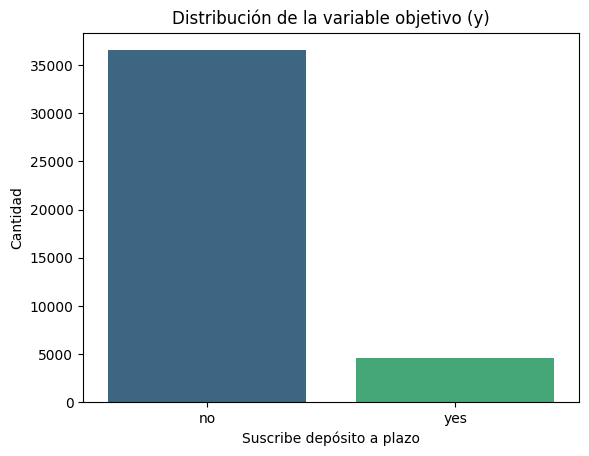

,proportion
y,
no,0.887346
yes,0.112654


In [9]:
sns.countplot(x='y', data=df, palette='viridis')
plt.title('Distribución de la variable objetivo (y)')
plt.xlabel('Suscribe depósito a plazo')
plt.ylabel('Cantidad')
plt.show()

# Proporciones
df['y'].value_counts(normalize=True)

>**Pregunta:**
>¿Qué conclusiones puedes obtener de la distribución de la variable objetivo?
>
>La mayoría de los registros corresponde a clientes que no contrataron el depósito a plazo (“no”). Hay muy pocos casos de “yes”, lo que muestra que la variable objetivo está desbalanceada y puede complicar el análisis y la predicción de la clase minoritaria.

## Etapa 2: Preprocesamiento de los Datos
---
### 2.1 Análisis y Tratamiento de Valores Faltantes

In [10]:
# Valores faltantes tradicionales y como 'unknown'
print(df.isnull().sum())
print((df == 'unknown').sum())

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64
age                  0
job                330
marital             80
education         1731
default           8597
housing            990
loan               990
contact              0
month                0
day_of_week          0
duration             0
campaign             0
pdays                0
previous             0
poutcome             0
emp.var.rate         0
cons.price.idx       0
cons.conf.idx        0
euribor3m            0
nr.employed          0
y                    0
dtype: int64


In [11]:
# Eliminar filas con 'unknown' en variables importantes
df_clean = df[(df['job'] != 'unknown') & (df['education'] != 'unknown') & (df['marital'] != 'unknown')]

### 2.2 Codificación de Variables Categóricas

In [12]:
# Codificación One-Hot para variables categóricas
df_encoded = pd.get_dummies(df_clean, drop_first=True)

### 2.3 División en Entrenamiento y Prueba

In [13]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop('y_yes', axis=1)
y = df_encoded['y_yes']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Entrenamiento: {X_train.shape} - Prueba: {X_test.shape}')

Entrenamiento: (31352, 50) - Prueba: (7839, 50)


> **Pregunta:** ¿Por qué es fundamental realizar una división del conjunto de datos antes de entrenar el modelo?
>
> Es fundamental para evitar sobreajuste y poder evaluar el desempeño real sobre datos que el modelo nunca vio. Así, nos aseguramos de medir cómo generaliza y no sólo cómo memoriza los datos de entrenamiento.

## Etapa 3: Transformación de los Datos
---
### 3.1 Selección y Escalado de Variables Predictoras

In [14]:
from sklearn.preprocessing import StandardScaler

# Selección de variables sugeridas
caracteristicas = ['previous', 'pdays', 'emp.var.rate', 'euribor3m']
X_train_sel = X_train[caracteristicas]
X_test_sel = X_test[caracteristicas]

# Escalado
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_sel)
X_test_scaled = scaler.transform(X_test_sel)

> **Pregunta:** ¿Qué beneficio tiene escalar o normalizar los datos antes del entrenamiento del modelo?
>
> Escalar los datos permite que todas las variables tengan igual peso, evitando que unas dominen a otras debido a su rango. Esto mejora la estabilidad y desempeño de la regresión logística.

#### Gráfico de Distribución (antes y después del escalado)

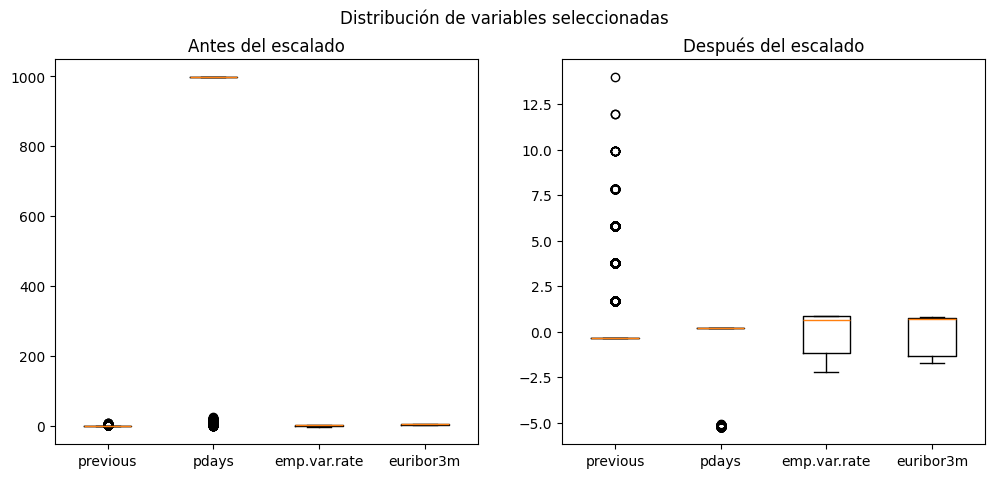

In [15]:
# Comparación visual antes y después del escalado
fig, axs = plt.subplots(1, 2, figsize=(12,5))
axs[0].boxplot(X_train_sel.values, tick_labels=caracteristicas)
axs[0].set_title('Antes del escalado')
axs[1].boxplot(X_train_scaled, tick_labels=caracteristicas)
axs[1].set_title('Después del escalado')
plt.suptitle('Distribución de variables seleccionadas')
plt.show()

## Etapa 4: Minería de Datos
---
### 4.1 Entrenamiento del Modelo de Regresión Logística

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

### 4.2 Métricas y Evaluación

Precisión (Accuracy): 0.899221839520347

Matriz de Confusión:
 [[6877   90]
 [ 700  172]]

Informe de Clasificación:
               precision    recall  f1-score   support

       False       0.91      0.99      0.95      6967
        True       0.66      0.20      0.30       872

    accuracy                           0.90      7839
   macro avg       0.78      0.59      0.62      7839
weighted avg       0.88      0.90      0.87      7839



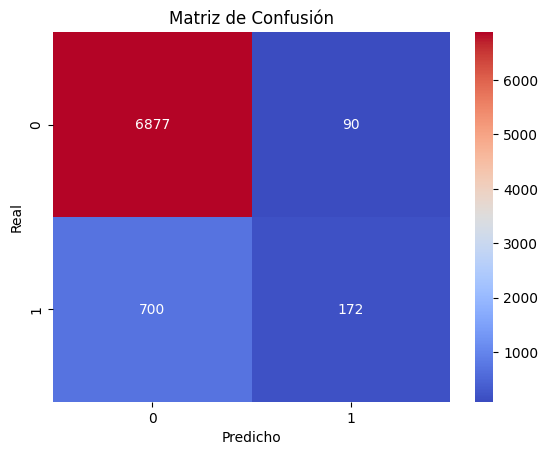

In [ ]:
print('Precisión (Accuracy):', accuracy_score(y_test, y_pred))
print('\nMatriz de Confusión:\n', confusion_matrix(y_test, y_pred))
print('\nInforme de Clasificación:\n', classification_report(y_test, y_pred))

# Visualizar la matriz de confusión
graf_conf = sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='coolwarm')
plt.title('Matriz de Confusión')
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.show()

>**Pregunta:**
¿Cuál es la precisión del modelo obtenido y cómo la interpretarías en el contexto específico del problema de predicción de aceptación de un depósito a plazo por parte de los clientes?
>
>La precisión del modelo indica el porcentaje de predicciones correctas sobre el total. Sin embargo, como el dataset está desbalanceado (la mayoría es “no”), una precisión alta puede significar que el modelo solo acierta diciendo “no” casi siempre. Por eso, en este caso, es importante mirar también métricas como el recall y el F1-score para la clase “yes”, que es la que realmente le interesa al banco para identificar posibles nuevos clientes.

> **Nota:** como referencia, un modelo que respondiera siempre "no" obtendría ≈ 88,9 % de accuracy (6.967 de 7.839 casos de prueba). El 89,9 % obtenido supera apenas esa línea base, por lo que el indicador relevante es el recall de la clase "yes" (0,20).

## Etapa 5: Interpretación y Evaluación
---
### 5.1 Pruebas variando el hiperparámetro C

In [17]:
for C in [0.1, 1, 10]:
    print(f'\n----- Modelo con C={C} -----')
    model_C = LogisticRegression(C=C, max_iter=1000, random_state=42)
    model_C.fit(X_train_scaled, y_train)
    y_pred_C = model_C.predict(X_test_scaled)
    print('Precisión:', accuracy_score(y_test, y_pred_C))
    print('Reporte de Clasificación:\n', classification_report(y_test, y_pred_C))


----- Modelo con C=0.1 -----
Precisión: 0.899221839520347
Reporte de Clasificación:
               precision    recall  f1-score   support

       False       0.91      0.99      0.95      6967
        True       0.66      0.20      0.30       872

    accuracy                           0.90      7839
   macro avg       0.78      0.59      0.62      7839
weighted avg       0.88      0.90      0.87      7839


----- Modelo con C=1 -----
Precisión: 0.899221839520347
Reporte de Clasificación:
               precision    recall  f1-score   support

       False       0.91      0.99      0.95      6967
        True       0.66      0.20      0.30       872

    accuracy                           0.90      7839
   macro avg       0.78      0.59      0.62      7839
weighted avg       0.88      0.90      0.87      7839


----- Modelo con C=10 -----
Precisión: 0.899221839520347
Reporte de Clasificación:
               precision    recall  f1-score   support

       False       0.91      0.99   

> **Pregunta:** ¿Cuál configuración consideras más adecuada y por qué? ¿Cómo afecta el parámetro C al modelo?
>
> El hiperparámetro C controla la regularización:
> - C bajo: más regularización, menos riesgo de sobreajuste pero menos ajuste a los datos.
> - C alto: menos regularización, el modelo se ajusta más pero puede sobreajustar.
> La mejor configuración es la que logra el mejor balance entre precisión y recall para la clase "yes".